# Association between the clusters of the three schemes

The 159 conversations come from 78 students, so they are not independent. Association is therefore
reported with Cramér's V and a bootstrap that resamples students, p-values from a permutation that
shuffles each student's labels as a block, and a per-activity analysis where every student contributes
exactly one conversation. The ARI is reported descriptively.

* **Input:** `cluster_assignments.csv`, `source/activities.csv`
* **Output:** `results/tables/association_*.csv`, heatmaps and alluvial diagram in `results/figures/`
* **Check:** 159 conversations from 78 students, never two in the same activity

## ENVIRONMENTAL VARIABLES

In [2]:
from pathlib import Path
import os

import numpy as np
import pandas as pd

# Dataset to work on: 'data' is the study data, 'data_example' the synthetic example.
DATA = Path('..') / os.environ.get('DATASET_FOLDER', 'data')

CODING_SCHEMES = [
                 'acosta_epistemic_stance',
                 'del_bosque_cma',
                 'lin_dialogue_acts'
                ]

In [3]:
activities = pd.read_csv(DATA / 'source' / 'activities.csv').set_index('activity_id')

df = pd.read_csv(DATA / 'cluster_assignments.csv')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   activity_id  159 non-null    object
 1   user_id      159 non-null    object
 2   da_cluster   159 non-null    int64 
 3   es_cluster   159 non-null    int64 
 4   cma_cluster  159 non-null    int64 
dtypes: int64(3), object(2)
memory usage: 6.3+ KB


In [4]:
df['conv_id'] = df.index

aux = df[['conv_id', 'es_cluster', 'da_cluster', 'cma_cluster']].copy()
aux.head()

,conv_id,es_cluster,da_cluster,cma_cluster
0,0,0,0,1
1,1,0,1,0
2,2,1,2,1
3,3,1,1,2
4,4,1,2,1


In [5]:
print(df.es_cluster.value_counts(normalize=True))
print(df.cma_cluster.value_counts(normalize=True))
print(df.da_cluster.value_counts(normalize=True))

es_cluster
1    0.465409
2    0.295597
0    0.238994
Name: proportion, dtype: float64
cma_cluster
0    0.364780
2    0.358491
1    0.276730
Name: proportion, dtype: float64
da_cluster
1    0.540881
2    0.364780
0    0.094340
Name: proportion, dtype: float64


## Cross-scheme comparison

Cramér's V, the chi-square it is based on, and the ARI for each pair of schemes. The asymptotic
p-value is printed for reference only: it assumes independent observations, which is corrected
further down.

In [6]:
import plotly.graph_objects as go
from scipy.stats import chi2_contingency
from itertools import combinations
from sklearn.metrics import adjusted_rand_score

# NAME THE PROFILES (as in the manuscript)
da_names  = {0:"Extended-engagement", 1:"Task-completion", 2:"Front-loading"}
es_names  = {0:"Assignment-driven", 1:"Gap-filling", 2:"Sense-making"}
cma_names = {0:"Tutored", 1:"Passive", 2:"Collaborative"}

d = aux.copy()
d["DA"]  = d["da_cluster"].map(da_names)
d["ES"]  = d["es_cluster"].map(es_names)
d["CMA"] = d["cma_cluster"].map(cma_names)

# ASSOCIATION STATS
def cramers_v(ct):
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r,k = ct.shape
    return np.sqrt((chi2/n) / (min(r-1,k-1)))

pairs = {"DA":"da_cluster","ES":"es_cluster","CMA":"cma_cluster"}
print("Pairwise association (n=%d):" % len(d))
for a,b in combinations(["DA","ES","CMA"],2):
    ct = pd.crosstab(d[a], d[b])
    chi2,p,dof,exp = chi2_contingency(ct)
    v = cramers_v(ct)
    ari = adjusted_rand_score(d[pairs[a]], d[pairs[b]])
    small = (exp < 5).mean()*100
    print(f"  {a}x{b}: Cramér's V={v:.3f}  chi2={chi2:.2f} dof={dof:.2f} p={p:.10f}  "
          f"ARI={ari:.3f}  ({small:.0f}% cells exp<5 -> use Fisher/permutation if high)")

Pairwise association (n=159):
  DAxES: Cramér's V=0.335  chi2=35.68 dof=4.00 p=0.0000003370  ARI=0.068  (22% cells exp<5 -> use Fisher/permutation if high)
  DAxCMA: Cramér's V=0.351  chi2=39.14 dof=4.00 p=0.0000000652  ARI=0.097  (11% cells exp<5 -> use Fisher/permutation if high)
  ESxCMA: Cramér's V=0.386  chi2=47.36 dof=4.00 p=0.0000000013  ARI=0.131  (0% cells exp<5 -> use Fisher/permutation if high)


In [7]:
# NORMALIZED CROSS-TABS
for a,b in combinations(["DA","ES","CMA"],2):
    print(f"\nRow-normalized {a} -> {b} (%):")
    print((pd.crosstab(d[a], d[b], normalize="index")*100).round(1))


Row-normalized DA -> ES (%):
ES                   Assignment-driven  Gap-filling  Sense-making
DA                                                               
Extended-engagement                6.7         13.3          80.0
Front-loading                     36.2         56.9           6.9
Task-completion                   18.6         45.3          36.0

Row-normalized DA -> CMA (%):
CMA                  Collaborative  Passive  Tutored
DA                                                  
Extended-engagement           80.0     20.0      0.0
Front-loading                 12.1     48.3     39.7
Task-completion               44.2     15.1     40.7

Row-normalized ES -> CMA (%):
CMA                Collaborative  Passive  Tutored
ES                                                
Assignment-driven           10.5     50.0     39.5
Gap-filling                 25.7     24.3     50.0
Sense-making                72.3     14.9     12.8


In [8]:
# MOST COMMON JOINT PROFILES (feeds the case analysis)
print("Top joint (DA,ES,CMA) profiles:")
print(d.groupby(["DA","ES","CMA"]).size().sort_values(ascending=False).head(8))

Top joint (DA,ES,CMA) profiles:
DA                   ES                 CMA          
Task-completion      Sense-making       Collaborative    22
                     Gap-filling        Tutored          21
Front-loading        Gap-filling        Tutored          16
                     Assignment-driven  Passive          14
Task-completion      Gap-filling        Collaborative    12
Extended-engagement  Sense-making       Collaborative    11
Front-loading        Gap-filling        Passive          11
Task-completion      Assignment-driven  Tutored           8
dtype: int64


## Heatmaps of the row-normalized cross-tabulations

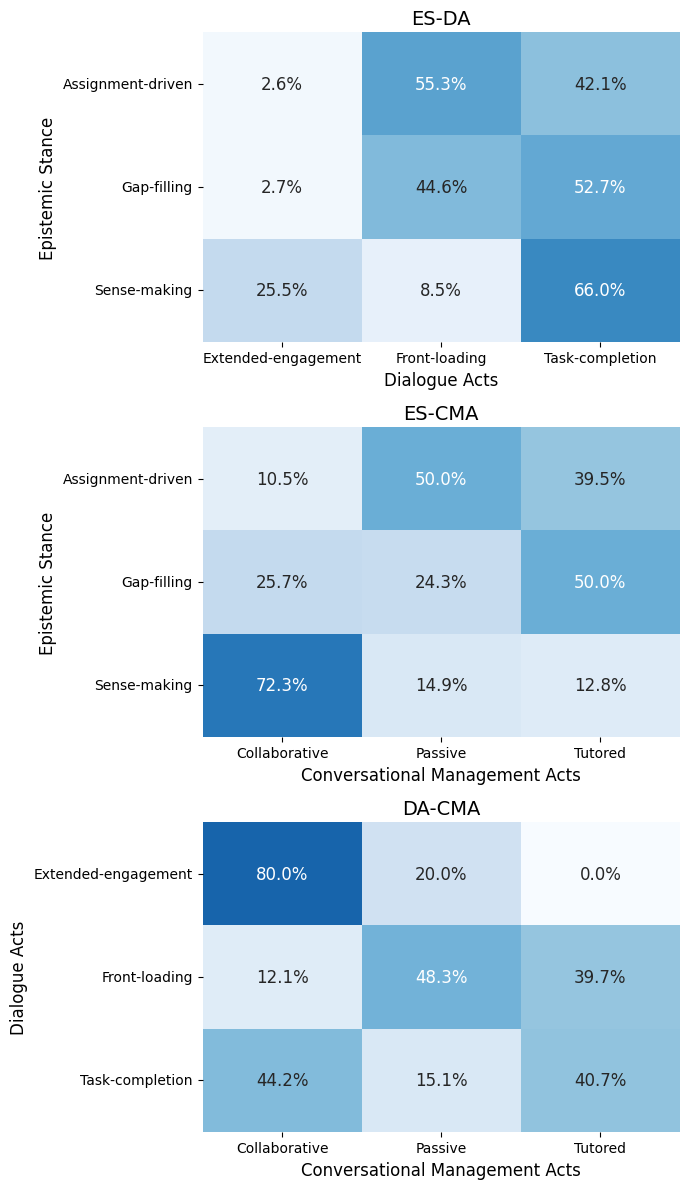

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

path_figures = DATA / 'results' / 'figures'
path_tables = DATA / 'results' / 'tables'
path_figures.mkdir(parents=True, exist_ok=True)
path_tables.mkdir(parents=True, exist_ok=True)

table_es_da_named = pd.crosstab(d['ES'], d['DA'], normalize='index')
table_es_cma_named = pd.crosstab(d['ES'], d['CMA'], normalize='index')
table_da_cma_named = pd.crosstab(d['DA'], d['CMA'], normalize='index')

# Stacked vertically so the long profile names have room and don't overlap.
fig, axes = plt.subplots(3, 1, figsize=(7, 12))

sns.heatmap(table_es_da_named, annot=True, fmt='.1%', cmap='Blues',
            vmin=0, vmax=1, cbar=False, ax=axes[0], annot_kws={'size': 12})
axes[0].set_xlabel('Dialogue Acts', fontsize=12)
axes[0].set_ylabel('Epistemic Stance', fontsize=12)
axes[0].set_title('ES-DA', fontsize=14)
axes[0].tick_params(axis='x', rotation=0)

sns.heatmap(table_es_cma_named, annot=True, fmt='.1%', cmap='Blues',
            vmin=0, vmax=1, cbar=False, ax=axes[1], annot_kws={'size': 12})
axes[1].set_ylabel('Epistemic Stance', fontsize=12)
axes[1].set_xlabel('Conversational Management Acts', fontsize=12)
axes[1].set_title('ES-CMA', fontsize=14)
axes[1].tick_params(axis='x', rotation=0)

sns.heatmap(table_da_cma_named, annot=True, fmt='.1%', cmap='Blues',
            vmin=0, vmax=1, cbar=False, ax=axes[2], annot_kws={'size': 12})
axes[2].set_title('DA-CMA', fontsize=14)
axes[2].set_ylabel('Dialogue Acts', fontsize=12)
axes[2].set_xlabel('Conversational Management Acts', fontsize=12)
axes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(path_figures / 'crosstab_heatmaps.png', dpi=200, bbox_inches='tight')
plt.show()

## Alluvial diagram of the joint distribution

In [10]:
fig = go.Figure(go.Parcats(

    dimensions=[
        go.parcats.Dimension(values=d["DA"],  label="Dialogue Acts",
                             categoryorder="category descending"),
        go.parcats.Dimension(values=d["ES"],  label="Epistemic Stance",
                             categoryorder="category descending"),
        go.parcats.Dimension(values=d["CMA"], label="Conversation Management Acts",
                             categoryorder="category descending"),
    ],
    line={"color": d["es_cluster"], "colorscale":"Viridis", "shape":"hspline"},
    hoveron="color", arrangement="freeform",
    labelfont={"size":13}, tickfont={"size":11},
))
fig.update_layout(width=880, height=520, margin=dict(l=150,r=150,t=40,b=20))

output_path = path_figures / "parcats.html"
fig.write_html(str(output_path))
print(f"Parcats written to {output_path}")

fig.show()

Parcats written to ../data/results/figures/parcats.html


# Independence of the units

Added while answering the reviewers. The three chi-square tests above are computed over 159
conversations that come from 78 students, who contribute between one and three conversations each
(median 2); only 27 of the 78 contribute a single conversation. The rows of the contingency tables are
therefore not independent and the asymptotic p-value is anti-conservative.

The correction keeps Cramér's V as the descriptive measure and adds

1. a confidence interval from a **bootstrap that resamples students, not conversations**,
2. a p-value from a **permutation that exchanges whole students' label vectors**, only between
   students with an identical set of activities, so a conversation never receives a label drawn from
   another activity,
3. a **per-activity analysis**, where each student contributes exactly one conversation, so
   independence holds exactly and an ordinary permutation is valid.

In [11]:
from scipy.stats import kruskal
from statsmodels.stats.multitest import multipletests

RNG = np.random.default_rng(20240501)   # fixed: permutation p-values are reproducible
N_PERM_POOLED = 10000
N_PERM_ACTIVITY = 5000
N_BOOT = 2000

SCHEME_COLS = {'ES': 'es_cluster', 'CMA': 'cma_cluster', 'DA': 'da_cluster'}

units = df[['activity_id', 'user_id'] + list(SCHEME_COLS.values())].dropna().copy()
units = units.sort_values(['user_id', 'activity_id']).reset_index(drop=True)

per_student = units['user_id'].value_counts()
print('=== Unit structure behind the contingency tables ===')
print(f'conversations          : {len(units)}')
print(f'distinct students      : {units["user_id"].nunique()}')
print(f'distinct activities    : {units["activity_id"].nunique()}')
print(f'conversations/student  : min={per_student.min()}, median={per_student.median():.0f}, '
      f'max={per_student.max()}')
print('\ndistribution of conversations per student:')
print(per_student.value_counts().sort_index()
      .rename_axis('conversations_contributed').to_frame('n_students').to_string())

dup_within_activity = (units.groupby(['activity_id', 'user_id']).size() > 1).any()
print(f'\nany student contributing >1 conversation to the SAME activity? {dup_within_activity}')

print('\nrows per activity:')
print(units.groupby('activity_id').agg(n_conversations=('user_id', 'size'),
                                       n_students=('user_id', 'nunique')).to_string())

=== Unit structure behind the contingency tables ===
conversations          : 159
distinct students      : 78
distinct activities    : 4
conversations/student  : min=1, median=2, max=3

distribution of conversations per student:
                           n_students
conversations_contributed            
1                                  27
2                                  21
3                                  30

any student contributing >1 conversation to the SAME activity? False

rows per activity:
                               n_conversations  n_students
activity_id                                               
asst_Get3WE5ozTjkHcdGhnqGGqgL               52          52
asst_ZZ2f7t77l5PKcfG6pHkVMQDz               35          35
asst_ncmAPAoB3MT4TIBrhhRAjpJ9               23          23
asst_xRGU7Xk0G1eHkruFzY1kpaTO               49          49


## Machinery: fast chi-square, student blocks, and the exchange strata

In [12]:
def chi2_from_codes(a_codes, b_codes, n_a, n_b):
    """Pearson chi-square (no continuity correction) straight from integer codes."""
    ct = np.bincount(a_codes * n_b + b_codes, minlength=n_a * n_b).reshape(n_a, n_b)
    n = ct.sum()
    exp = ct.sum(1, keepdims=True) * ct.sum(0, keepdims=True) / n
    with np.errstate(divide='ignore', invalid='ignore'):
        return np.where(exp > 0, (ct - exp) ** 2 / exp, 0.0).sum()

def cramers_v_from_table(ct):
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    r, k = ct.shape
    return np.sqrt((chi2 / n) / min(r - 1, k - 1))

# Each student's row indices, ordered by activity; strata group students whose
# activity SET is identical, so an exchanged block lines up activity-for-activity.
blocks = {u: g.index.values for u, g in units.groupby('user_id', sort=False)}
activity_set = units.groupby('user_id')['activity_id'].apply(lambda s: tuple(sorted(s)))
strata = {s: list(g.index) for s, g in activity_set.groupby(activity_set)}

print('=== Student-block exchange strata (students sharing an identical activity set) ===')
strata_tbl = pd.DataFrame([{'n_activities': len(s), 'n_students': len(u)}
                           for s, u in strata.items()]).sort_values(
                           ['n_activities', 'n_students'], ascending=[True, False])
print(strata_tbl.to_string(index=False))
print(f'\nstudents in a stratum of size 1 (never exchanged, contribute no permutation '
      f'variability): {sum(len(u) for u in strata.values() if len(u) < 2)}')

def block_permute(values):
    """Exchange ENTIRE student blocks within a stratum. Conversation-level labels
    are never shuffled, so within-student dependence is preserved under the null."""
    out = values.copy()
    for users in strata.values():
        if len(users) < 2:
            continue
        order = RNG.permutation(len(users))
        for dest, src in zip(users, [users[i] for i in order]):
            out[blocks[dest]] = values[blocks[src]]
    return out

=== Student-block exchange strata (students sharing an identical activity set) ===
 n_activities  n_students
            1           9
            1           7
            1           7
            1           4
            2           9
            2           4
            2           4
            2           2
            2           2
            3          18
            3          12

students in a stratum of size 1 (never exchanged, contribute no permutation variability): 0


## Pooled analysis: V with a student cluster bootstrap, p by block permutation

In [13]:
codes = {name: pd.factorize(units[col], sort=True) for name, col in SCHEME_COLS.items()}
students = units['user_id'].unique()

rows = []
for a, b in combinations(SCHEME_COLS, 2):
    a_codes, a_levels = codes[a][0], codes[a][1]
    b_codes, b_levels = codes[b][0], codes[b][1]
    n_a, n_b = len(a_levels), len(b_levels)

    ct = pd.crosstab(units[SCHEME_COLS[a]], units[SCHEME_COLS[b]])
    chi2_asym, p_asym, dof, expected = chi2_contingency(ct)
    observed = chi2_from_codes(a_codes, b_codes, n_a, n_b)
    v = cramers_v_from_table(ct)

    null = np.array([chi2_from_codes(a_codes, block_permute(b_codes), n_a, n_b)
                     for _ in range(N_PERM_POOLED)])
    p_block = (1 + (null >= observed).sum()) / (N_PERM_POOLED + 1)

    boot = []
    for _ in range(N_BOOT):
        pick = RNG.choice(students, size=len(students), replace=True)
        bd = units.loc[np.concatenate([blocks[u] for u in pick])]
        bt = pd.crosstab(bd[SCHEME_COLS[a]], bd[SCHEME_COLS[b]])
        if min(bt.shape) > 1:
            boot.append(cramers_v_from_table(bt))
    lo, hi = np.percentile(boot, [2.5, 97.5])

    rows.append({'pair': f'{a} x {b}', 'chi2': observed, 'dof': dof,
                 'cramers_V': v, 'V_ci_low': lo, 'V_ci_high': hi,
                 'p_asymptotic': p_asym, 'p_block_perm': p_block,
                 'perm_null_mean': null.mean(), 'perm_null_sd': null.std(),
                 'chi2_ref_mean': dof, 'chi2_ref_sd': np.sqrt(2 * dof),
                 'ari': adjusted_rand_score(units[SCHEME_COLS[a]], units[SCHEME_COLS[b]]),
                 'pct_cells_exp_lt5': 100 * (expected < 5).mean()})

pooled = pd.DataFrame(rows)
pooled.round(4).to_csv(path_tables / 'association_pooled.csv', index=False)

print('=== 159 conversations nested in 78 students ===')
print(pooled[['pair', 'chi2', 'dof', 'cramers_V', 'V_ci_low', 'V_ci_high',
              'p_asymptotic', 'p_block_perm', 'ari']].round(4).to_string(index=False))
print(f'\n(V interval = percentile 95% CI from {N_BOOT} bootstrap resamples OF STUDENTS;')
print(f' p_block_perm from {N_PERM_POOLED} student-block permutations, so its floor is '
      f'{1/(N_PERM_POOLED+1):.1e})')

print('\n=== How much the clustering inflates the reference distribution ===')
print(pooled[['pair', 'perm_null_mean', 'chi2_ref_mean',
              'perm_null_sd', 'chi2_ref_sd']].round(3).to_string(index=False))

=== 159 conversations nested in 78 students ===
    pair    chi2  dof  cramers_V  V_ci_low  V_ci_high  p_asymptotic  p_block_perm    ari
ES x CMA 47.3578    4     0.3859    0.2878     0.5021           0.0        0.0001 0.1306
 ES x DA 35.6782    4     0.3350    0.2620     0.4136           0.0        0.0001 0.0677
CMA x DA 39.1406    4     0.3508    0.2786     0.4359           0.0        0.0001 0.0965

(V interval = percentile 95% CI from 2000 bootstrap resamples OF STUDENTS;
 p_block_perm from 10000 student-block permutations, so its floor is 1.0e-04)

=== How much the clustering inflates the reference distribution ===
    pair  perm_null_mean  chi2_ref_mean  perm_null_sd  chi2_ref_sd
ES x CMA           5.069              4         3.448        2.828
 ES x DA           4.328              4         2.979        2.828
CMA x DA           5.773              4         3.640        2.828


## Per-activity check

Exactly one conversation per student, so independence holds and a conversation-level permutation is
legitimate. Holm-Bonferroni corrects across the four activities within each pair of schemes.

In [14]:
rows = []
for activity, g in units.groupby('activity_id'):
    for a, b in combinations(SCHEME_COLS, 2):
        ct = pd.crosstab(g[SCHEME_COLS[a]], g[SCHEME_COLS[b]])
        if min(ct.shape) < 2:
            continue
        chi2_asym, p_asym, dof, expected = chi2_contingency(ct)
        ac, al = pd.factorize(g[SCHEME_COLS[a]], sort=True)
        bc, bl = pd.factorize(g[SCHEME_COLS[b]], sort=True)
        observed = chi2_from_codes(ac, bc, len(al), len(bl))
        null = np.array([chi2_from_codes(ac, RNG.permutation(bc), len(al), len(bl))
                         for _ in range(N_PERM_ACTIVITY)])
        rows.append({'activity': activities.loc[activity, 'activity_name'], 'pair': f'{a} x {b}',
                     'n': len(g),
                     'cramers_V': cramers_v_from_table(ct),
                     'pct_cells_exp_lt5': 100 * (expected < 5).mean(),
                     'p_asymptotic': p_asym,
                     'p_perm': (1 + (null >= observed).sum()) / (N_PERM_ACTIVITY + 1)})

per_activity = pd.DataFrame(rows)
# Holm across the four activities, within each scheme pair.
per_activity['p_perm_holm'] = np.nan
for pair, g in per_activity.groupby('pair'):
    per_activity.loc[g.index, 'p_perm_holm'] = multipletests(g['p_perm'], method='holm')[1]

per_activity.round(4).to_csv(path_tables / 'association_per_activity.csv', index=False)

print('=== Per-activity replication (one conversation per student => independent) ===')
print(per_activity.round(4).to_string(index=False))
print('\nThe two large activities carry the result; the two small ones (n=23, n=35)')
print('have most cells with an expected count below 5 and are underpowered - read those')
print('rows as absence of power, not as evidence of no association.')

=== Per-activity replication (one conversation per student => independent) ===
 activity     pair  n  cramers_V  pct_cells_exp_lt5  p_asymptotic  p_perm  p_perm_holm
Summary 5 ES x CMA 52     0.4891            33.3333        0.0001  0.0002       0.0008
Summary 5  ES x DA 52     0.5097            44.4444        0.0000  0.0002       0.0008
Summary 5 CMA x DA 52     0.5308            44.4444        0.0000  0.0002       0.0008
Summary 3 ES x CMA 35     0.3972            77.7778        0.0261  0.0224       0.0672
Summary 3  ES x DA 35     0.3517            77.7778        0.0702  0.0606       0.1212
Summary 3 CMA x DA 35     0.3146            66.6667        0.1397  0.1406       0.2811
Summary 2 ES x CMA 23     0.4701           100.0000        0.0378  0.0318       0.0672
Summary 2  ES x DA 23     0.2874            77.7778        0.4339  0.4951       0.4951
Summary 2 CMA x DA 23     0.3520           100.0000        0.2227  0.2320       0.2811
Summary 4 ES x CMA 49     0.2313            55.5556